# E-Commerce Sales Analysis

**Problem:** The company faces operational problems that hurt growth and customer satisfaction. We analyse revenue, customers, logistics, products, cancellations and returns, and give recommendations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

In [2]:
from google.colab import files
uploaded = files.upload()

In [3]:
df = pd.read_csv('sales_dataset.csv')
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(128949, 23)


/tmp/ipykernel_91/962373353.py:1: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('sales_dataset.csv')


,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


## 2. Data exploration

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128949 entries, 0 to 128948
Data columns (total 23 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Order ID            128949 non-null  str    
 1   Date                128949 non-null  str    
 2   Status              128949 non-null  str    
 3   Fulfilment          128949 non-null  str    
 4   Sales Channel       128949 non-null  str    
 5   ship-service-level  128949 non-null  str    
 6   Style               128949 non-null  str    
 7   SKU                 128949 non-null  str    
 8   Category            128949 non-null  str    
 9   Size                128949 non-null  str    
 10  ASIN                128949 non-null  str    
 11  Courier Status      122078 non-null  str    
 12  Qty                 128949 non-null  int64  
 13  currency            121155 non-null  str    
 14  Amount              121155 non-null  float64
 15  ship-city           128916 non-null  str    


In [5]:
df.isnull().sum()

Order ID                  0
Date                      0
Status                    0
Fulfilment                0
Sales Channel             0
ship-service-level        0
Style                     0
SKU                       0
Category                  0
Size                      0
ASIN                      0
Courier Status         6871
Qty                       0
currency               7794
Amount                 7794
ship-city                33
ship-state               33
ship-postal-code         33
ship-country             33
promotion-ids         49142
B2B                       0
fulfilled-by          89679
Unnamed: 22           49041
dtype: int64

In [6]:
print('Duplicate rows:', df.duplicated().sum())
print('Unique Order IDs:', df['Order ID'].nunique())

Duplicate rows: 6
Unique Order IDs: 120352


In [7]:
for col in ['Status', 'Fulfilment', 'Sales Channel', 'ship-service-level', 'Category', 'Size', 'B2B']:
    print(df[col].value_counts(dropna=False))
    print()

Status
Shipped                          77767
Shipped - Delivered to Buyer     28771
Cancelled                        18341
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64

Fulfilment
Amazon      89679
Merchant    39270
Name: count, dtype: int64

Sales Channel
Amazon.in     128825
Non-Amazon       124
Name: count, dtype: int64

ship-service-level
Expedited    88596
Standard     40353
Name: count, dtype: int64

Category
Set              50275
kurta            49867
Western Dress    15495
Top              10621
Ethnic Dress      1158
Blouse             926
Bottom             440
Saree              164
Dupatta              3
Na

In [8]:
df[['Qty', 'Amount']].describe()

,Qty,Amount
count,128949.000000,121155.000000
mean,0.904629,648.550806
std,0.314782,281.218324
min,0.000000,0.000000
25%,1.000000,449.000000
50%,1.000000,605.000000
75%,1.000000,788.000000
max,15.000000,5584.000000


In [9]:
df['Date'].str.len().value_counts()

Date
8     73852
10    55097
Name: count, dtype: int64

## 3. Data cleaning

In [10]:
df = df.drop('Unnamed: 22', axis=1)
df = df.drop_duplicates()
print(df.shape)

(128943, 22)


In [11]:
df = df.rename(columns={'Fulfilment': 'Fulfillment',
                        'Qty': 'Quantity',
                        'promotion-ids': 'promotion_ids',
                        'fulfilled-by': 'fulfilled_by'})

In [12]:
df['Date'] = pd.to_datetime(df['Date'], format='mixed')
print(df['Date'].min())
print(df['Date'].max())

2022-03-31 00:00:00
2022-06-29 00:00:00


In [13]:
df = df.fillna({'ship-city': 'Unknown', 'ship-state': 'Unknown', 'ship-country': 'Unknown',
                'ship-postal-code': 0, 'promotion_ids': 'Unknown', 'Courier Status': 'Unknown',
                'fulfilled_by': 'Unknown', 'currency': 'Unknown'})

df['Category'] = df['Category'].str.title()
df['ship-city'] = df['ship-city'].str.title()
df['ship-state'] = df['ship-state'].str.title()

df.isnull().sum()[df.isnull().sum() > 0]

Amount    7791
dtype: int64

In [14]:
df['Amount_raw'] = df['Amount']
df['Amount'] = df['Amount'].fillna(df['Amount'].median())
print(df['Amount'].median())

605.0


In [15]:
df['Month'] = df['Date'].dt.strftime('%Y-%m')
df['Week'] = df['Date'].dt.to_period('W').astype(str)
df['is_cancelled'] = df['Status'] == 'Cancelled'
df['is_returned'] = df['Status'].isin(['Shipped - Returned to Seller', 'Shipped - Returning to Seller', 'Shipped - Rejected by Buyer'])

**Revenue** is counted only from non-cancelled orders, because a cancelled order brings no money.

In [16]:
sales = df[df['is_cancelled'] == False]

print('All rows after median fill      :', round(df['Amount'].sum()))
print('Non-cancelled after median fill :', round(sales['Amount'].sum()))
print('Non-cancelled without fill      :', round(sales['Amount_raw'].sum()))

All rows after median fill      : 83286093
Non-cancelled after median fill : 71786174
Non-cancelled without fill      : 71646419


## 4. Financial performance

Month
2022-03       95415.00
2022-04    26284149.62
2022-05    23986391.00
2022-06    21420218.00
Name: Amount, dtype: float64
Month
2022-03     95415.000000
2022-04    876138.320667
2022-05    773754.548387
2022-06    738628.206897
dtype: float64


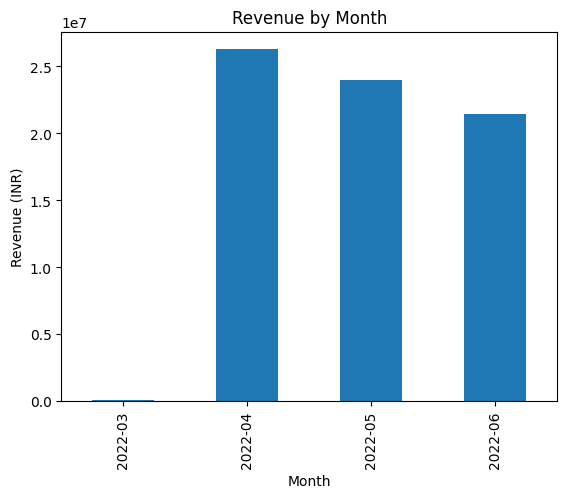

In [17]:
monthly_revenue = sales.groupby('Month')['Amount'].sum()
days = sales.groupby('Month')['Date'].nunique()

print(monthly_revenue)
print(monthly_revenue / days)

monthly_revenue.plot(kind='bar')
plt.title('Revenue by Month')
plt.ylabel('Revenue (INR)')
plt.show()

March has only 1 day of data, and the data covers about 3 months, so a yearly seasonal pattern cannot be studied.

Category
Set              35783725.14
Kurta            19479334.48
Western Dress    10208945.00
Top               4909572.00
Ethnic Dress       732121.00
Blouse             420809.00
Bottom             136058.00
Saree              114694.00
Dupatta               915.00
Name: Amount, dtype: float64
Category
Set              49.847656
Kurta            27.135218
Western Dress    14.221325
Top               6.839161
Ethnic Dress      1.019864
Blouse            0.586198
Bottom            0.189532
Saree             0.159772
Dupatta           0.001275
Name: Amount, dtype: float64


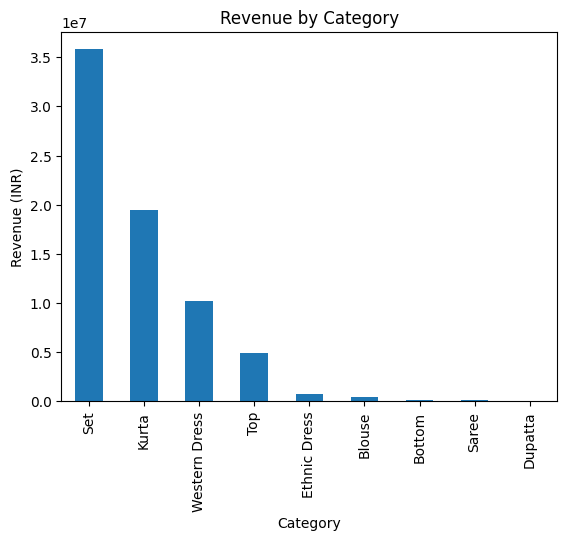

In [18]:
category_revenue = sales.groupby('Category')['Amount'].sum().sort_values(ascending=False)

print(category_revenue)
print(category_revenue / category_revenue.sum() * 100)

category_revenue.plot(kind='bar')
plt.title('Revenue by Category')
plt.ylabel('Revenue (INR)')
plt.show()

In [19]:
sales.groupby('Style')['Quantity'].sum().sort_values(ascending=False).head(10)

Style
JNE3797    3601
JNE3405    1936
J0230      1606
SET268     1601
J0341      1397
J0003      1341
SET324     1092
SET345     1067
JNE3373     996
JNE3399     900
Name: Quantity, dtype: int64

**Average Order Value (AOV)** = Total revenue of non-cancelled orders / Number of unique non-cancelled Order IDs

In [20]:
total_revenue = sales['Amount'].sum()
total_orders = sales['Order ID'].nunique()

print('Total revenue:', round(total_revenue))
print('Unique non-cancelled orders:', total_orders)
print('Average Order Value (AOV):', round(total_revenue / total_orders, 2))

Total revenue: 71786174
Unique non-cancelled orders: 103158
Average Order Value (AOV): 695.89


## 5. Customer insights

ship-state
Maharashtra       12234616.00
Karnataka          9648629.00
Telangana          6294073.57
Uttar Pradesh      6184815.00
Tamil Nadu         5959537.00
Delhi              4008480.48
Kerala             3378842.00
West Bengal        3208355.00
Andhra Pradesh     2887107.00
Haryana            2655292.00
Name: Amount, dtype: float64
ship-state
Maharashtra       17.043137
Karnataka         13.440790
Telangana          8.767808
Uttar Pradesh      8.615608
Tamil Nadu         8.301789
Delhi              5.583917
Kerala             4.706814
West Bengal        4.469322
Andhra Pradesh     4.021815
Haryana            3.698891
Name: Amount, dtype: float64


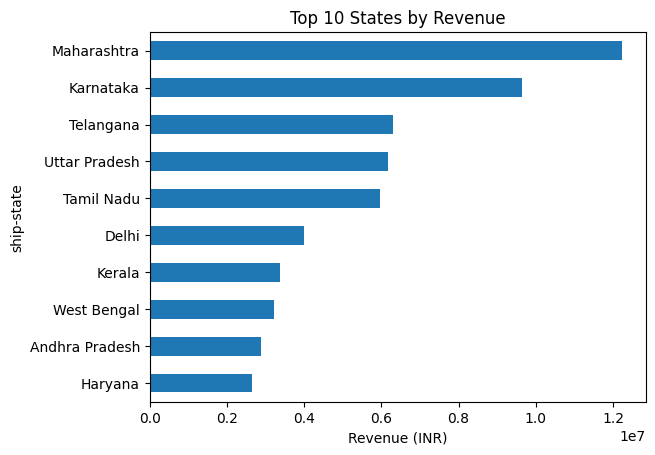

In [21]:
state_revenue = sales.groupby('ship-state')['Amount'].sum().sort_values(ascending=False)

print(state_revenue.head(10))
print(state_revenue.head(10) / state_revenue.sum() * 100)

state_revenue.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 States by Revenue')
plt.xlabel('Revenue (INR)')
plt.show()

In [22]:
total = df.groupby('B2B')['Order ID'].nunique()
cancelled = df[df['is_cancelled']].groupby('B2B')['Order ID'].nunique()

b2b = pd.DataFrame({'total_orders': total, 'cancelled_orders': cancelled})
b2b['cancel_rate_%'] = b2b['cancelled_orders'] / b2b['total_orders'] * 100
b2b['revenue'] = sales.groupby('B2B')['Amount'].sum()
b2b

,total_orders,cancelled_orders,cancel_rate_%,revenue
B2B,,,,
False,119558,17130,14.327774,71226168.62
True,794,66,8.312343,560005.00


Customer retention cannot be measured because the data has no customer ID.

## 6. Logistics and fulfillment

In [23]:
total = df.groupby('Fulfillment')['Order ID'].nunique()
cancelled = df[df['is_cancelled']].groupby('Fulfillment')['Order ID'].nunique()

fulfillment = pd.DataFrame({'total_orders': total, 'cancelled_orders': cancelled})
fulfillment['cancel_rate_%'] = fulfillment['cancelled_orders'] / fulfillment['total_orders'] * 100
fulfillment['returned_rows'] = sales.groupby('Fulfillment')['is_returned'].sum()
fulfillment['revenue'] = sales.groupby('Fulfillment')['Amount'].sum()
fulfillment

,total_orders,cancelled_orders,cancel_rate_%,returned_rows,revenue
Fulfillment,,,,,
Amazon,83983,10811,12.872843,0,50703370.00
Merchant,36369,6385,17.556160,2109,21082803.62


In [24]:
df['Status'].value_counts()

Status
Shipped                          77764
Shipped - Delivered to Buyer     28771
Cancelled                        18338
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64

Average shipping time cannot be calculated because the data has no ship or delivery date.

## 7. Product management and inventory

In [25]:
print(sales.groupby('Category')['Quantity'].sum().sort_values(ascending=False))
print('Average quantity per row:', round(sales['Quantity'].mean(), 3))

Category
Set              43024
Kurta            42786
Western Dress    13414
Top               9366
Ethnic Dress      1014
Blouse             832
Bottom             384
Saree              147
Dupatta              3
Name: Quantity, dtype: int64
Average quantity per row: 1.003


In [26]:
size_order = ['XS', 'S', 'M', 'L', 'XL', 'XXL', '3XL', '4XL', '5XL', '6XL', 'Free']
size_quantity = sales.groupby('Size')['Quantity'].sum().reindex(size_order)

print(size_quantity)
print(size_quantity / size_quantity.sum() * 100)

Size
XS       9322
S       14530
M       19392
L       19029
XL      18072
XXL     15740
3XL     12990
4XL       380
5XL       495
6XL       665
Free      355
Name: Quantity, dtype: int64
Size
XS       8.400469
S       13.093629
M       17.474993
L       17.147878
XL      16.285483
XXL     14.184014
3XL     11.705866
4XL      0.342435
5XL      0.446067
6XL      0.599261
Free     0.319906
Name: Quantity, dtype: float64


## 8. Cancellation analysis

**Cancellation Rate = Monthly Cancelled Orders / Total Monthly Orders x 100**

An order is the unique Order ID. An order is counted as cancelled if its status is Cancelled.

In [27]:
total_orders = df['Order ID'].nunique()
cancelled_orders = df[df['is_cancelled']]['Order ID'].nunique()

print('Total orders:', total_orders)
print('Total Cancelled Orders:', cancelled_orders)
print('Overall cancellation rate:', round(cancelled_orders / total_orders * 100, 2), '%')

Total orders: 120352
Total Cancelled Orders: 17196
Overall cancellation rate: 14.29 %


In [28]:
monthly_total = df.groupby('Month')['Order ID'].nunique()
monthly_cancelled = df[df['is_cancelled']].groupby('Month')['Order ID'].nunique()

cancel_month = pd.DataFrame({'total_orders': monthly_total, 'cancelled_orders': monthly_cancelled})
cancel_month['cancel_rate_%'] = cancel_month['cancelled_orders'] / cancel_month['total_orders'] * 100
cancel_month

,total_orders,cancelled_orders,cancel_rate_%
Month,,,
2022-03,158,18,11.392405
2022-04,45849,6730,14.678619
2022-05,39216,5491,14.001938
2022-06,35129,4957,14.110849


In [29]:
df.groupby('Month')['is_cancelled'].mean() * 100

Month
2022-03    10.526316
2022-04    14.548679
2022-05    13.989341
2022-06    14.072285
Name: is_cancelled, dtype: float64

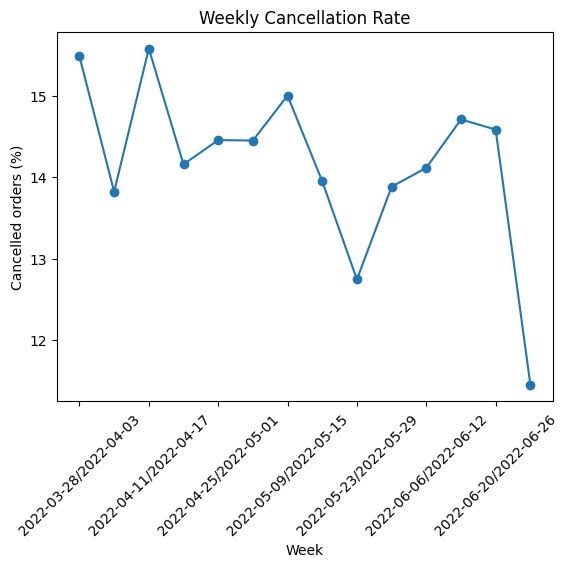

In [30]:
weekly_total = df.groupby('Week')['Order ID'].nunique()
weekly_cancelled = df[df['is_cancelled']].groupby('Week')['Order ID'].nunique()
weekly_rate = weekly_cancelled / weekly_total * 100

weekly_rate.plot(marker='o')
plt.title('Weekly Cancellation Rate')
plt.ylabel('Cancelled orders (%)')
plt.xticks(rotation=45)
plt.show()

In [31]:
for col in ['Category', 'Size']:
    total = df.groupby(col)['Order ID'].nunique()
    cancelled = df[df['is_cancelled']].groupby(col)['Order ID'].nunique()

    result = pd.DataFrame({'total_orders': total, 'cancelled_orders': cancelled}).fillna(0)
    result['cancel_rate_%'] = result['cancelled_orders'] / result['total_orders'] * 100
    print(result.sort_values('cancel_rate_%', ascending=False))
    print()

               total_orders  cancelled_orders  cancel_rate_%
Category                                                    
Kurta                 46551            6822.0      14.654895
Set                   47836            6991.0      14.614516
Saree                   144              21.0      14.583333
Western Dress         14989            2073.0      13.830142
Bottom                  410              54.0      13.170732
Ethnic Dress           1147             145.0      12.641674
Blouse                  897             113.0      12.597547
Top                   10154            1231.0      12.123301
Dupatta                   2               0.0       0.000000

      total_orders  cancelled_orders  cancel_rate_%
Size                                               
XS           10529              1776      16.867699
S            16339              2492      15.251851
M            21716              3232      14.883036
L            21051              3005      14.274856
XL           198

## 9. Returns and problematic products

In [32]:
returned_orders = sales[sales['is_returned']]['Order ID'].nunique()

print('Returned orders:', returned_orders)
print('Return rate:', round(returned_orders / sales['Order ID'].nunique() * 100, 2), '%')
print(df[df['is_returned']]['Status'].value_counts())

Returned orders: 1992
Return rate: 1.93 %
Status
Shipped - Returned to Seller     1953
Shipped - Returning to Seller     145
Shipped - Rejected by Buyer        11
Name: count, dtype: int64


In [33]:
style_total = df.groupby('Style')['Order ID'].nunique()
style_cancelled = df[df['is_cancelled']].groupby('Style')['Order ID'].nunique()
style_rate = style_cancelled / style_total * 100

style_rate[style_total >= 200].sort_values(ascending=False).head(10)

Style
JNE3365    22.123894
J0244      20.640569
JNE3461    20.491803
JNE3805    20.161290
SET396     20.091324
JNE2014    19.181034
SET357     18.970190
JNE3611    18.939394
JNE3721    18.813314
SET377     18.719212
Name: Order ID, dtype: float64

These 10 styles have cancellation rates of about 19% to 22%, against 14.3% overall. Only styles with at least 200 orders are used. They are all Kurta or Set, and Merchant orders cancel more than Amazon orders, so stock and pickup for these styles should be checked.

## 10. Key Insights
- Revenue from non-cancelled orders is about Rs 7.18 crore. Revenue per day fell about 16% from April to June.
- Set and Kurta give about 77% of revenue. The Average Order Value is Rs 695.89.
- 17,196 of 120,352 orders were cancelled (14.29%), and the rate stays about the same each month.
- Merchant (Easy Ship) orders cancel more than Amazon orders (17.56% vs 12.87%). All returns (1.93% of orders) are in Merchant orders.
- Sizes S to 3XL are about 98% of sales. XS has the highest cancellation rate (16.87%).

## 11. Recommendations
1. Find out why Merchant / Easy Ship orders are cancelled more, and move more orders to faster shipping.
2. Keep strong stock of Set and Kurta in sizes S to 3XL. Order 4XL to 6XL, Free size and the small categories (Saree, Blouse, Bottom, Dupatta) in small quantities.
3. Check stock and pickup for the high-cancellation styles listed above.
4. Find out why daily revenue is falling, and collect customer ID, delivery dates and return reasons.

## 12. Conclusion
Sales depend on a few categories, sizes and states. The main problems are the steady 14% cancellation rate, which is worse for Merchant orders, and the fall in daily revenue. Fixing fulfillment and matching stock to demand are the best next steps. These results use only about 3 months of data.